In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Kaggle dataset
df = pd.read_csv("../data/spam.csv", encoding="latin-1")

# Display the first five rows
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [2]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

Dataset shape: (5572, 5)

Column names:
['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB


In [3]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

# Calculate missing-value percentages
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing-value percentage:")
print(missing_percentage.round(2))

Missing values in each column:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Missing-value percentage:
v1             0.00
v2             0.00
Unnamed: 2    99.10
Unnamed: 3    99.78
Unnamed: 4    99.89
dtype: float64


In [4]:
# Display five random messages
df.sample(5, random_state=42)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
3245,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t...",NaN,NaN,NaN
944,ham,I sent my scores to sophas and i had to do sec...,NaN,NaN,NaN
1044,spam,We know someone who you know that fancies you....,NaN,NaN,NaN
2484,ham,Only if you promise your getting out as SOON a...,NaN,NaN,NaN
812,spam,Congratulations ur awarded either å£500 of CD ...,NaN,NaN,NaN


In [5]:
# Count messages in each category
label_counts = df["v1"].value_counts()

print(label_counts)

# Calculate percentages
label_percentages = df["v1"].value_counts(normalize=True) * 100

print("\nClass percentages:")
print(label_percentages.round(2))

v1
ham     4825
spam     747
Name: count, dtype: int64

Class percentages:
v1
ham     86.59
spam    13.41
Name: proportion, dtype: float64


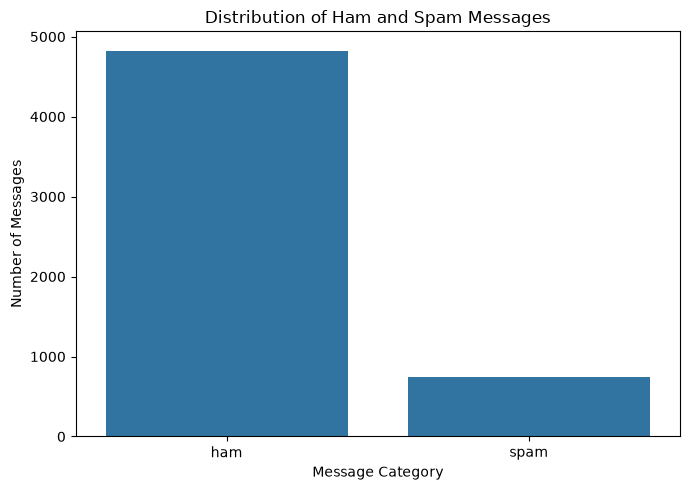

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="v1")

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()

In [7]:
# Calculate the number of characters in each message
df["message_length"] = df["v2"].apply(len)

# Display descriptive statistics
print("Overall message length statistics:")
print(df["message_length"].describe())

Overall message length statistics:
count    5572.000000
mean       80.118808
std        59.690841
min         2.000000
25%        36.000000
50%        61.000000
75%       121.000000
max       910.000000
Name: message_length, dtype: float64


In [8]:
# Compare character counts for ham and spam
print(
    df.groupby("v1")["message_length"]
    .describe()
    .round(2)
)

       count    mean    std   min    25%    50%    75%    max
v1                                                           
ham   4825.0   71.02  58.02   2.0   33.0   52.0   92.0  910.0
spam   747.0  138.87  29.18  13.0  132.5  149.0  157.0  224.0


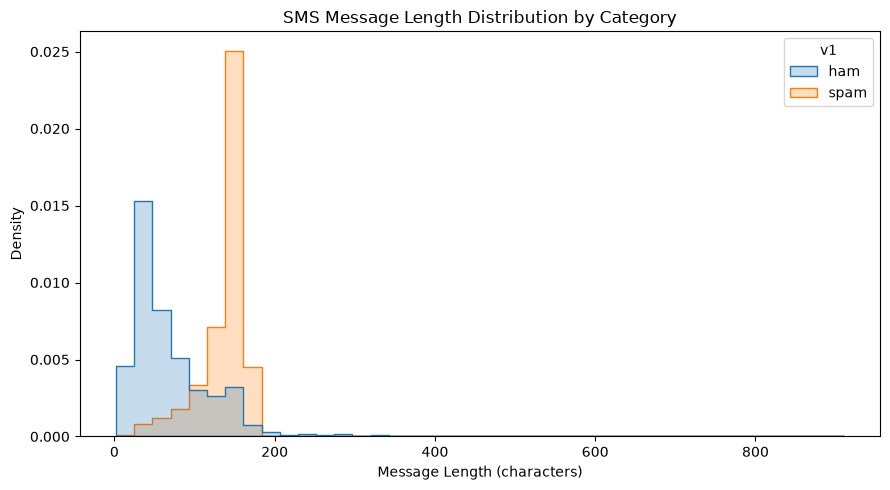

In [9]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="message_length",
    hue="v1",
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("SMS Message Length Distribution by Category")
plt.xlabel("Message Length (characters)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

### Key Findings from Data Exploration

1.The dataset contains 5,572 SMS messages and five original columns.

2.The v1 column contains the target labels (ham and spam), while v2 contains message text.

3.The three Unnamed columns contain mostly missing values and are not required for our classification task.

4.The dataset contains 4,825 ham messages (86.59%) and 747 spam messages (13.41%), indicating class imbalance.

5.The average message length is approximately 71 characters for ham and 139 characters for spam.

6.Some ham messages are unusually long, with the maximum length reaching 910 characters.

### Conclusion

The dataset is suitable for a binary text-classification task. Because of the class imbalance, model evaluation should include spam precision, spam recall, and F1-score alongside accuracy.

The next stage is data preprocessing, where we will select the relevant columns, investigate duplicate records, prepare the target labels, and split the dataset into training and testing sets.